In [144]:
from pathlib import Path
import pandas as pd
from sympy.functions.special import delta_functions



def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")

ROOT = find_project_root()
DATASETS_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets"
volume_100 = pd.read_parquet(DATASETS_DIR / "BTCUSDT_spot_volume_2650_25pd_20210901-20260901_99bf72d5/volume.parquet")

In [145]:
def set_datetime_index(df):
    return df.set_index(
        pd.to_datetime(df["bar_end_us"], unit="us", utc=True)
    ).sort_index().rename_axis("datetime")

df = set_datetime_index(volume_100)
df = df[~df.index.duplicated(keep='first')]

In [146]:
train = df[df.index<'2024']
holdout = df[df.index>='2024']

In [147]:
"""Trade-event extraction for four strategies:

* donchian_breakout_continuation: Strategy 432 BTC (Pine v6).
* rsi_cross_above: RSI crosses above a threshold, exit on cross below.
* tis_btc_momentum_confluence: TIS - BTC Momentum + Confluencia (Pine v6).
* supertrend_regime_confluence: DefinedEdge SuperTrend Regime Confluence (Pine v6).

Input: one chronological OHLC bar series with microsecond timestamps.
Output: only CLOSED trades; each row preserves features from the ENTRY SIGNAL bar.

Conservative HTF handling: aggregate available bars into *completed* UTC HTF
candles and publish their momentum only after the full HTF period has ended.
This is purposefully stricter than TradingView's historical request.security(...,
lookahead_off) mapping. Volume bars spanning HTF boundaries make reconstructed
HTF candles approximate; use genuine daily OHLC if exact equivalence is needed.

Default execution is next eligible bar open, after decision_time/bar_available.
Set execution='signal_close' for a Pine-like optimistic bar-close fill.
"""

import numpy as np
import pandas as pd


def _wilder_rma(values, length):
    """Wilder RMA, SMA seeded; values expected to belong to a single segment."""
    a = np.asarray(values, dtype=float)
    out = np.full(len(a), np.nan, dtype=float)
    total, count, prev = 0.0, 0, np.nan
    for i, val in enumerate(a):
        if not np.isfinite(val):
            total, count, prev = 0.0, 0, np.nan
            continue
        if count < length:
            total += val
            count += 1
            if count == length:
                prev = total / length
                out[i] = prev
        else:
            prev = (prev * (length - 1) + val) / length
            out[i] = prev
    return out


def _rsi_wilder(close, length):
    change = np.diff(close, prepend=np.nan)
    avg_gain = _wilder_rma(np.maximum(change, 0.0), length)
    avg_loss = _wilder_rma(np.maximum(-change, 0.0), length)
    out = np.full(len(close), np.nan, dtype=float)
    ready = np.isfinite(avg_gain) & np.isfinite(avg_loss)
    positive = ready & (avg_loss > 0)
    out[positive] = 100.0 - 100.0 / (1.0 + avg_gain[positive] / avg_loss[positive])
    out[ready & (avg_loss == 0) & (avg_gain > 0)] = 100.0
    out[ready & (avg_loss == 0) & (avg_gain == 0)] = 50.0
    return out


def _atr_wilder(high, low, close, length):
    previous_close = np.r_[np.nan, close[:-1]]
    true_range = np.maximum.reduce([
        high - low,
        np.abs(high - previous_close),
        np.abs(low - previous_close),
    ])
    true_range[0] = high[0] - low[0]
    return _wilder_rma(true_range, length)


def _higher_timeframe_momentum(bars, indices, start_us, end_us, ready_us,
                               streak_length, htf, boundary_tolerance_hours):
    """Map confirmed higher-timeframe green streaks back onto lower-timeframe bars.

    A higher-TF candle is built from lower-timeframe OHLC whose *end* belongs
    to its UTC time bucket. Its close is revealed only at/after the bucket's
    end, not at the last known intraday bar. Buckets missing a boundary by more
    than `boundary_tolerance_hours` are treated as incomplete and reset streak.
    """
    idx = np.asarray(indices, dtype=int)
    green_htf = np.zeros(len(idx), dtype=bool)
    htf_streak = np.zeros(len(idx), dtype=np.int32)
    if len(idx) == 0:
        return green_htf, htf_streak

    duration = pd.Timedelta(htf)
    duration_us = duration.value // 1000
    if duration_us <= 0:
        raise ValueError("htf must be a positive fixed timeframe, e.g. '1D' or '4h'")

    # UTC epoch-aligned fixed-timeframe buckets.
    period = (end_us[idx].astype(np.int64) - 1) // duration_us
    unique_periods, first_idx = np.unique(period, return_index=True)
    last_idx = np.r_[first_idx[1:] - 1, len(idx) - 1]
    o = bars["open"].to_numpy(dtype=float)
    c = bars["close"].to_numpy(dtype=float)

    confirmations = []
    confirmed_streaks = []
    streak = 0
    previous_period = None
    tolerance_us = int(boundary_tolerance_hours * 3_600_000_000)
    for key, a, b in zip(unique_periods, first_idx, last_idx):
        rows = idx[a:b + 1]
        period_start = int(key * duration_us)
        period_end = period_start + duration_us

        if previous_period is not None and int(key) != previous_period + 1:
            # A missing calendar bucket must break the HTF consecutive-day streak.
            streak = 0
        previous_period = int(key)

        # Verify that the source data plausibly covers this entire HTF bucket.
        # This does not prove tick-level completeness for bars spanning a boundary.
        covers_start = start_us[rows[0]] <= period_start + tolerance_us
        covers_end = end_us[rows[-1]] >= period_end - tolerance_us
        if covers_start and covers_end:
            streak = streak + 1 if c[rows[-1]] > o[rows[0]] else 0
        else:
            streak = 0

        ready_at = max(period_end, int(np.max(ready_us[rows])))
        confirmations.append(ready_at)
        confirmed_streaks.append(streak)

    confirmations = np.asarray(confirmations, dtype=np.int64)
    confirmed_streaks = np.asarray(confirmed_streaks, dtype=np.int32)
    # Binary search ensures HTF values are unavailable until their confirmation.
    known = np.searchsorted(confirmations, ready_us[idx], side="right") - 1
    good = known >= 0
    htf_streak[good] = confirmed_streaks[known[good]]
    green_htf[good] = htf_streak[good] >= streak_length
    return green_htf, htf_streak


def strategy_events(
    df,
    strategy="rsi_cross_above",
    *,
    # RSI strategy parameters
    rsi_length=14,
    rsi_level=70.0,
    # TIS Momentum + Confluence parameters (Pine defaults)
    ma_length=50,
    streak_length=3,
    atr_length=14,
    atr_mult=3.0,
    risk_pct=1.0,
    tail_mult=2.0,
    conf_mult=1.5,
    htf="1D",
    cap_pct=40.0,
    initial_capital=None,
    htf_boundary_tolerance_hours=1.5,
    # Common execution parameters
    fee_bps=None,
    slippage_ticks=None,
    tick_size=0.1,
    execution="next_open",
    # SuperTrend Regime Confluence (DefinedEdge) parameters (Pine defaults)
    st_atr_length=10,
    st_base_multiplier=3.0,
    st_source="hl2",
    regime_lookback=40,
    adx_length=14,
    adx_threshold=20.0,
    adaptive_multiplier=True,
    trend_ema_length=50,
    volume_ma_length=20,
    volume_column="volume",
    min_signal_score=65,
    size_mode="Risk %",
    st_risk_pct=5.0,
    equity_pct=15.0,
    fixed_units=1.0,
    no_leverage=True,
    sl_mode="ATR",
    sl_atr_mult=6.0,
    sl_pct=3.0,
    tp_mode="RR",
    tp_rr=2.5,
    tp_pct=6.0,
    trailing_stop=False,
    trail_atr_mult=2.5,
    use_trend_filter=True,
    skip_ranging=True,
    use_volume_filter=True,
    cooldown_bars=5,
    allow_longs=True,
    allow_shorts=None,
    bt_from="2015-01-01",
    bt_to="2035-01-01",
    # Strategy 432 BTC: Donchian Breakout Continuation
    dc_length=30,
    ema200_length=200,
    min_break_atr=0.5,
    dc_adx_min=22.0,
    hold_bars=20,
    dc_equity_pct=95.0,
):
    """Return one row for every closed strategy trade, with entry-signal features.

    Strategy 432: strategy="donchian_breakout_continuation" (alias
    "strategy_432_btc"). Use execution="signal_close" for the supplied Pine's
    process_orders_on_close=true. Common default remains "next_open".
    Shorts default off for 432, on for SuperTrend. Donchian uses prior bars only;
    exits are close-based (no intrabar stop/TP), hold_bars starts at signal bar.
    Fractional quantity; no exchange lot rounding, funding or margin liquidation.

    TIS entry: close > SMA(ma_length), >= streak_length green lower-TF bars,
      AND >= streak_length green fully confirmed HTF candles.
    TIS exit: close < SMA OR (open-close) > tail_mult * ATR.
    TIS qty: min(equity * risk_pct/100 / (ATR * atr_mult) * conf_mult,
                 equity * cap_pct/100 / signal_close).
    IMPORTANT: ATR*atr_mult is only used for SIZING. The Pine script contains
    NO protective ATR stop order. There is no portfolio leverage assumption.

    `trade_return` is net return per dollar of ENTRY NOTIONAL; `pnl_usd` is
    actual money PnL for the sized position. Equity is updated upon trade exits.
    RSI maintains one long position at a time. TIS is also long-only, no overlap.

    'signal_close' mimics TradingView's process_orders_on_close but can be
    optimistic and is NOT a guarantee of causal real-world fillability.
    """
    if strategy in ("donchian_breakout_continuation", "strategy_432_btc"):
        return _donchian_breakout_continuation_events(
            df, dc_length=dc_length, atr_length=atr_length,
            adx_length=adx_length, ema200_length=ema200_length,
            min_break_atr=min_break_atr, dc_adx_min=dc_adx_min,
            hold_bars=hold_bars, equity_pct=dc_equity_pct,
            allow_longs=allow_longs,
            allow_shorts=False if allow_shorts is None else allow_shorts,
            initial_capital=10_000.0 if initial_capital is None else initial_capital,
            fee_bps=10.0 if fee_bps is None else fee_bps,
            slippage_ticks=0 if slippage_ticks is None else slippage_ticks,
            tick_size=tick_size, execution=execution,
        )
    # Preserve SuperTrend's original short-enabled default.
    if allow_shorts is None:
        allow_shorts = True
    if strategy == "supertrend_regime_confluence":
        return _supertrend_regime_confluence_events(
            df,
            st_atr_length=st_atr_length,
            st_base_multiplier=st_base_multiplier,
            st_source=st_source,
            regime_lookback=regime_lookback,
            adx_length=adx_length,
            adx_threshold=adx_threshold,
            adaptive_multiplier=adaptive_multiplier,
            trend_ema_length=trend_ema_length,
            volume_ma_length=volume_ma_length,
            volume_column=volume_column,
            min_signal_score=min_signal_score,
            size_mode=size_mode,
            st_risk_pct=st_risk_pct,
            equity_pct=equity_pct,
            fixed_units=fixed_units,
            no_leverage=no_leverage,
            sl_mode=sl_mode,
            sl_atr_mult=sl_atr_mult,
            sl_pct=sl_pct,
            tp_mode=tp_mode,
            tp_rr=tp_rr,
            tp_pct=tp_pct,
            trailing_stop=trailing_stop,
            trail_atr_mult=trail_atr_mult,
            use_trend_filter=use_trend_filter,
            skip_ranging=skip_ranging,
            use_volume_filter=use_volume_filter,
            cooldown_bars=cooldown_bars,
            allow_longs=allow_longs,
            allow_shorts=allow_shorts,
            bt_from=bt_from,
            bt_to=bt_to,
            initial_capital=10_000.0 if initial_capital is None else initial_capital,
            fee_bps=6.0 if fee_bps is None else fee_bps,
            slippage_ticks=2 if slippage_ticks is None else slippage_ticks,
            tick_size=tick_size,
            execution=execution,
        )
    if initial_capital is None:
        initial_capital = 100_000.0
    choices = ("rsi_cross_above", "tis_btc_momentum_confluence")
    if strategy not in choices:
        raise ValueError(f"Unknown strategy {strategy!r}; choose RSI/TIS, supertrend_regime_confluence, or donchian_breakout_continuation")
    if execution not in ("next_open", "signal_close"):
        raise ValueError("execution must be 'next_open' or 'signal_close'")
    for name, value, minimum in (
        ("rsi_length", rsi_length, 2),
        ("ma_length", ma_length, 2),
        ("streak_length", streak_length, 2),
        ("atr_length", atr_length, 1),
    ):
        if not isinstance(value, (int, np.integer)) or value < minimum:
            raise ValueError(f"{name} must be an integer >= {minimum}")
    if not (0 < rsi_level < 100):
        raise ValueError("rsi_level must be strictly between 0 and 100")
    for name, value in (
        ("atr_mult", atr_mult), ("risk_pct", risk_pct),
        ("tail_mult", tail_mult), ("conf_mult", conf_mult),
        ("cap_pct", cap_pct), ("initial_capital", initial_capital),
        ("htf_boundary_tolerance_hours", htf_boundary_tolerance_hours),
    ):
        if not np.isfinite(value) or value <= 0:
            raise ValueError(f"{name} must be finite and > 0")
    if not (0 < cap_pct <= 100):
        raise ValueError("cap_pct must be <= 100")
    # Preserve previous RSI defaults; TIS defaults match the supplied Pine script.
    if fee_bps is None:
        fee_bps = 5.0 if strategy == "rsi_cross_above" else 0.0
    if slippage_ticks is None:
        slippage_ticks = 0 if strategy == "rsi_cross_above" else 5
    if (not np.isfinite(fee_bps) or fee_bps < 0 or
        not isinstance(slippage_ticks, (int, np.integer)) or slippage_ticks < 0 or
        not np.isfinite(tick_size) or tick_size <= 0):
        raise ValueError("Invalid fee_bps, slippage_ticks or tick_size")
    try:
        if pd.Timedelta(htf).value <= 0:
            raise ValueError("htf duration must be positive")
    except (TypeError, ValueError) as exc:
        raise ValueError("htf must be a fixed timeframe such as '1D' or '4h'") from exc

    required = {"open", "high", "low", "close", "bar_start_us", "bar_end_us"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    for col in ("series_id", "bar_type"):
        if col in df.columns and df[col].nunique(dropna=False) > 1:
            raise ValueError(f"Expected only one {col} in input DataFrame")

    bars = df.sort_values("bar_start_us", kind="stable").reset_index(drop=True).copy()
    extras = [
        "strategy", "trade_id", "entry_side", "signal_time", "entry_time",
        "entry_price", "exit_time", "exit_price", "exit_reason",
        "trade_return_gross", "trade_return", "trade_return_pct", "label",
        "trade_status", "rsi_value", "sma_trend", "atr_value",
        "green_streak", "htf_green_streak", "htf_momentum",
        "position_qty", "position_notional_usd", "position_exposure_pct",
        "entry_equity_usd", "exit_equity_usd", "pnl_usd", "fees_usd",
        "holding_hours", "execution",
    ]
    columns = list(dict.fromkeys([*bars.columns, *extras]))
    if bars.empty:
        return pd.DataFrame(columns=columns)

    for col in ("open", "high", "low", "close"):
        bars[col] = pd.to_numeric(bars[col], errors="coerce")

    def microseconds(column, fallback=None):
        if column not in bars:
            return np.array(fallback, copy=True) if fallback is not None else None
        values = pd.to_numeric(bars[column], errors="coerce").to_numpy(dtype=float)
        if fallback is not None:
            values = np.where(np.isfinite(values), values, fallback)
        return values

    start = microseconds("bar_start_us")
    end = microseconds("bar_end_us")
    if not np.all(np.isfinite(start)) or np.any(np.diff(start) <= 0):
        raise ValueError("bar_start_us must be finite and strictly increasing")

    first = microseconds("first_trade_ts_us", start)
    available = microseconds("bar_available_us", end)
    decision = microseconds("decision_time_us", end)
    ready = np.maximum.reduce([end, available, decision])
    o, h, l, c = [bars[col].to_numpy(dtype=float) for col in ("open", "high", "low", "close")]
    valid = (
        np.isfinite(o) & np.isfinite(h) & np.isfinite(l) & np.isfinite(c)
        & np.isfinite(end) & np.isfinite(first) & np.isfinite(ready)
        & (o > 0) & (l > 0) & (l <= np.minimum(o, c))
        & (h >= np.maximum(o, c)) & (end >= start)
        & (first >= start) & (first <= end)
    )
    if "complete" in bars.columns:
        valid &= bars["complete"].fillna(False).astype(bool).to_numpy()

    n = len(bars)
    adjacent = np.zeros(n, dtype=bool)
    adjacent[1:] = valid[:-1] & valid[1:] & (start[1:] >= end[:-1])
    if "bar_seq" in bars.columns:
        seq = pd.to_numeric(bars["bar_seq"], errors="coerce").to_numpy(dtype=float)
        adjacent[1:] &= (np.isfinite(seq[1:]) & np.isfinite(seq[:-1])
                         & (seq[1:] == seq[:-1] + 1))
    if "segment_id" in bars.columns:
        s = bars["segment_id"]
        adjacent[1:] &= (s.iloc[1:].reset_index(drop=True).eq(
            s.iloc[:-1].reset_index(drop=True)).fillna(False).to_numpy(bool))

    run = np.cumsum(~adjacent)
    enter = np.zeros(n, dtype=bool)
    exit_ma = np.zeros(n, dtype=bool)
    exit_tail = np.zeros(n, dtype=bool)
    rsi_values = np.full(n, np.nan)
    sma_values = np.full(n, np.nan)
    atr_values = np.full(n, np.nan)
    streak_values = np.zeros(n, dtype=np.int32)
    htf_streak_values = np.zeros(n, dtype=np.int32)
    htf_momentum = np.zeros(n, dtype=bool)

    for _, group in bars.groupby(run, sort=False):
        idx = group.index.to_numpy()
        if not np.all(valid[idx]):
            continue
        gc = c[idx]
        if strategy == "rsi_cross_above":
            rv = _rsi_wilder(gc, rsi_length)
            previous = np.r_[np.nan, rv[:-1]]
            rsi_values[idx] = rv
            enter[idx] = (rv > rsi_level) & (previous <= rsi_level)
            exit_ma[idx] = (rv < rsi_level) & (previous >= rsi_level)
        else:
            sm = pd.Series(gc).rolling(ma_length, min_periods=ma_length).mean().to_numpy()
            atr = _atr_wilder(h[idx], l[idx], gc, atr_length)
            sma_values[idx] = sm
            atr_values[idx] = atr
            local_streak = 0
            for j, absolute_idx in enumerate(idx):
                local_streak = local_streak + 1 if gc[j] > o[absolute_idx] else 0
                streak_values[absolute_idx] = local_streak
            htf_ok, htf_counts = _higher_timeframe_momentum(
                bars, idx, start, end, ready,
                streak_length, htf, htf_boundary_tolerance_hours,
            )
            htf_streak_values[idx] = htf_counts
            htf_momentum[idx] = htf_ok
            enter[idx] = (
                (gc > sm) & (streak_values[idx] >= streak_length)
                & htf_ok & np.isfinite(atr) & (atr > 0)
            )
            exit_ma[idx] = (gc < sm) & np.isfinite(sm)
            exit_tail[idx] = ((o[idx] - gc) > tail_mult * atr) & np.isfinite(atr)

    fee = fee_bps / 10_000.0
    slip_usd_per_coin = slippage_ticks * tick_size
    equity = float(initial_capital)
    events = []
    position = None
    pending = None
    opened = 0
    censored_positions = 0
    discarded_pending_orders = 0
    unrealized_censored_pnl = 0.0

    def fill_price(raw, side, is_entry):
        # For a long, BUY incurs upward slippage and SELL downward slippage.
        return float(raw + (slip_usd_per_coin if is_entry else -slip_usd_per_coin))

    def planned_qty(signal_idx):
        if strategy == "rsi_cross_above":
            return 1.0  # RSI: original strategy has no explicit qty input.
        dist = atr_values[signal_idx] * atr_mult
        if (not np.isfinite(dist) or dist <= 0 or equity <= 0):
            return 0.0
        raw = (equity * risk_pct / 100.0 / dist) * conf_mult
        cap = (equity * cap_pct / 100.0) / c[signal_idx]
        return float(max(0, min(raw, cap)))

    def open_position(signal_idx, ts, raw_price, quantity):
        nonlocal position, opened, equity
        if quantity <= 0:
            return
        px = fill_price(raw_price, 1, True)
        if px <= 0:
            return
        entry_fee = quantity * px * fee
        equity -= entry_fee
        opened += 1
        position = dict(
            id=opened, signal_idx=signal_idx, ts=float(ts), price=px,
            qty=float(quantity), entry_fee=float(entry_fee),
            equity_before=float(equity + entry_fee),
        )

    def close_position(ts, raw_price, reason):
        nonlocal position, equity
        px = fill_price(raw_price, 1, False)
        if px <= 0:
            raise ValueError("Exit price became nonpositive after slippage")
        pos = position
        qty, p0 = pos["qty"], pos["price"]
        gross = px / p0 - 1.0
        entry_notional = qty * p0
        exit_fee = qty * px * fee
        fees = pos["entry_fee"] + exit_fee
        net = gross - fees / entry_notional
        pnl = qty * (px - p0) - fees
        equity += qty * (px - p0) - exit_fee
        signal_idx = pos["signal_idx"]
        event = bars.iloc[signal_idx].to_dict()
        event.update({
            "strategy": strategy,
            "trade_id": pos["id"],
            "entry_side": 1,
            "signal_time": pd.to_datetime(int(ready[signal_idx]), unit="us", utc=True),
            "entry_time": pd.to_datetime(int(pos["ts"]), unit="us", utc=True),
            "entry_price": p0,
            "exit_time": pd.to_datetime(int(ts), unit="us", utc=True),
            "exit_price": px,
            "exit_reason": reason,
            "trade_return_gross": gross,
            "trade_return": net,
            "trade_return_pct": net * 100.0,
            "label": int(pnl > 0),
            "trade_status": "closed",
            "rsi_value": rsi_values[signal_idx],
            "sma_trend": sma_values[signal_idx],
            "atr_value": atr_values[signal_idx],
            "green_streak": int(streak_values[signal_idx]),
            "htf_green_streak": int(htf_streak_values[signal_idx]),
            "htf_momentum": bool(htf_momentum[signal_idx]),
            "position_qty": qty,
            "position_notional_usd": entry_notional,
            "position_exposure_pct": 100 * entry_notional / pos["equity_before"],
            "entry_equity_usd": pos["equity_before"],
            "exit_equity_usd": equity,
            "pnl_usd": pnl,
            "fees_usd": fees,
            "holding_hours": (ts - pos["ts"]) / 3_600_000_000.0,
            "execution": execution,
        })
        events.append(event)
        position = None

    for i in range(n):
        if not valid[i] or (i > 0 and not adjacent[i]):
            if position is not None:
                censored_positions += 1
                # These positions are NOT added to closed trades. Their entry fee
                # had already been charged, so don't silently count a clean equity.
                if valid[i - 1] and i > 0:
                    unrealized_censored_pnl += position["qty"] * (c[i - 1] - position["price"])
            if pending is not None:
                discarded_pending_orders += 1
            position, pending = None, None
        if not valid[i]:
            continue

        # Next-open orders: require the original signal to be available BEFORE
        # the first trade of the chosen later bar.
        if (execution == "next_open" and pending is not None
                and i > pending["signal_idx"] and first[i] >= pending["ready_us"]):
            order = pending
            if order["action"] == "entry":
                open_position(order["signal_idx"], first[i], o[i], order["qty"])
            else:
                close_position(first[i], o[i], order["reason"])
            pending = None

        # Orders generated at this bar close.
        if pending is not None:
            continue
        if position is not None:
            if exit_ma[i] or exit_tail[i]:
                reason = (
                    "RSI_CROSS_BELOW_LEVEL" if strategy == "rsi_cross_above" else
                    "BELOW_SMA" if exit_ma[i] else "TAIL_CUT"
                )
                if execution == "signal_close":
                    close_position(end[i], c[i], reason)
                else:
                    pending = {"action": "exit", "signal_idx": i,
                               "ready_us": ready[i], "reason": reason}
        elif enter[i]:
            qty = planned_qty(i)
            if qty > 0:
                if execution == "signal_close":
                    open_position(i, end[i], c[i], qty)
                else:
                    pending = {"action": "entry", "signal_idx": i,
                               "ready_us": ready[i], "qty": qty}

    if position is not None:
        censored_positions += 1
    if pending is not None:
        discarded_pending_orders += 1

    result = pd.DataFrame(events, columns=columns).reset_index(drop=True)
    result.attrs.update({
        "censored_positions": censored_positions,
        "discarded_pending_orders": discarded_pending_orders,
        "total_opened_positions": opened,
        "execution": execution,
        "htf": htf if strategy == "tis_btc_momentum_confluence" else None,
        "htf_confirmation": "last completed UTC HTF candle, not developing candle",
        "remaining_realized_equity_usd": equity,
        "unrealized_censored_pnl_usd": unrealized_censored_pnl,
    })
    return result

def _supertrend_regime_confluence_events(
    df, *,
    st_atr_length, st_base_multiplier, st_source, regime_lookback,
    adx_length, adx_threshold, adaptive_multiplier,
    trend_ema_length, volume_ma_length, volume_column, min_signal_score,
    size_mode, st_risk_pct, equity_pct, fixed_units, no_leverage,
    sl_mode, sl_atr_mult, sl_pct, tp_mode, tp_rr, tp_pct,
    trailing_stop, trail_atr_mult, use_trend_filter, skip_ranging,
    use_volume_filter, cooldown_bars, allow_longs, allow_shorts,
    bt_from, bt_to, initial_capital, fee_bps, slippage_ticks,
    tick_size, execution,
):
    """SuperTrend Regime Confluence (DefinedEdge) event backtest.

    Signals are constructed on completed bars. Default Pine execution is the
    NEXT open, with original Pine's stop/TP anchored to the SIGNAL CLOSE.
    Uses conservative OHLC-only stop/target handling; intra-bar tick sequence
    is unknown. One row per CLOSED trade, attached to its ENTRY SIGNAL bar.
    """
    strategy = "supertrend_regime_confluence"

    ints = {
        "st_atr_length": (st_atr_length, 1),
        "regime_lookback": (regime_lookback, 2),
        "adx_length": (adx_length, 1),
        "trend_ema_length": (trend_ema_length, 2),
        "volume_ma_length": (volume_ma_length, 2),
        "min_signal_score": (min_signal_score, 0),
        "cooldown_bars": (cooldown_bars, 0),
    }
    for name, (v, minimum) in ints.items():
        if not isinstance(v, (int, np.integer)) or v < minimum:
            raise ValueError(f"{name} must be an integer >= {minimum}")
    if min_signal_score > 100:
        raise ValueError("min_signal_score must be <= 100")
    if size_mode not in {"Risk %", "Equity %", "Fixed Units"}:
        raise ValueError("size_mode must be 'Risk %', 'Equity %', or 'Fixed Units'")
    if sl_mode not in {"ATR", "Percent", "SuperTrend"}:
        raise ValueError("sl_mode must be ATR, Percent or SuperTrend")
    if tp_mode not in {"RR", "Percent", "None"}:
        raise ValueError("tp_mode must be RR, Percent or None")
    if st_source not in {"open", "high", "low", "close", "hl2", "hlc3", "ohlc4"}:
        raise ValueError("st_source must be a source among open/high/low/close/hl2/hlc3/ohlc4")
    if execution not in {"next_open", "signal_close"}:
        raise ValueError("execution must be next_open or signal_close")
    for name, val in {
        "st_base_multiplier": st_base_multiplier,
        "adx_threshold": adx_threshold,
        "st_risk_pct": st_risk_pct,
        "equity_pct": equity_pct,
        "sl_atr_mult": sl_atr_mult,
        "sl_pct": sl_pct,
        "tp_rr": tp_rr,
        "tp_pct": tp_pct,
        "trail_atr_mult": trail_atr_mult,
        "initial_capital": initial_capital,
        "tick_size": tick_size,
    }.items():
        if not np.isfinite(val) or val <= 0:
            raise ValueError(f"{name} must be finite > 0")
    if not np.isfinite(fixed_units) or fixed_units < 0:
        raise ValueError("fixed_units must be >= 0")
    if not np.isfinite(fee_bps) or fee_bps < 0:
        raise ValueError("fee_bps must be >= 0")
    if not isinstance(slippage_ticks, (int, np.integer)) or slippage_ticks < 0:
        raise ValueError("slippage_ticks must be a non-negative integer")
    if st_risk_pct > 100 or equity_pct > 100:
        raise ValueError("st_risk_pct and equity_pct must be <= 100")
    start_window = pd.Timestamp(bt_from)
    stop_window = pd.Timestamp(bt_to)
    if start_window.tzinfo is None:
        start_window = start_window.tz_localize("UTC")
    else:
        start_window = start_window.tz_convert("UTC")
    if stop_window.tzinfo is None:
        stop_window = stop_window.tz_localize("UTC")
    else:
        stop_window = stop_window.tz_convert("UTC")
    if not start_window < stop_window:
        raise ValueError("bt_from must be earlier than bt_to")

    required = {"open", "high", "low", "close", volume_column, "bar_start_us", "bar_end_us"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    for col in ("series_id", "bar_type"):
        if col in df.columns and df[col].nunique(dropna=False) > 1:
            raise ValueError(f"Input must have only one {col}")

    bars = df.sort_values("bar_start_us", kind="stable").reset_index(drop=True).copy()
    extras = [
        "strategy", "trade_id", "entry_side", "signal_time", "entry_time", "entry_price",
        "exit_time", "exit_price", "exit_reason", "trade_return_gross",
        "trade_return", "trade_return_pct", "label", "trade_status", "rsi_value",
        "sma_trend", "atr_value", "green_streak", "htf_green_streak", "htf_momentum",
        "position_qty", "position_notional_usd", "position_exposure_pct",
        "entry_equity_usd", "exit_equity_usd", "pnl_usd", "fees_usd",
        "holding_hours", "execution", "st_band", "st_direction", "st_regime",
        "st_atr_ratio", "st_adx", "st_ema", "st_vol_ma", "st_adapt_multiplier",
        "signal_score", "sl_price", "tp_price", "sl_distance",
        "tp_distance", "ambiguous_intrabar", "exit_time_is_bar_end_proxy",
        "position_sizing_mode", "trailing_activated",
    ]
    columns = list(dict.fromkeys([*bars.columns, *extras]))
    if bars.empty:
        out = pd.DataFrame(columns=columns)
        out.attrs["censored_positions"] = 0
        return out

    for name in ("open", "high", "low", "close", volume_column):
        bars[name] = pd.to_numeric(bars[name], errors="coerce")
    def usecs(col, fallback=None):
        if col not in bars:
            return np.array(fallback, copy=True) if fallback is not None else None
        v = pd.to_numeric(bars[col], errors="coerce").to_numpy(dtype=float)
        return np.where(np.isfinite(v), v, fallback) if fallback is not None else v

    start = usecs("bar_start_us")
    end = usecs("bar_end_us")
    if not np.isfinite(start).all() or np.any(np.diff(start) <= 0):
        raise ValueError("bar_start_us must be finite, unique and strictly increasing")
    first = usecs("first_trade_ts_us", start)
    available = usecs("bar_available_us", end)
    decision = usecs("decision_time_us", end)
    ready = np.maximum.reduce([end, available, decision])
    o, h, l, c, v = [bars[k].to_numpy(dtype=float) for k in
                     ("open", "high", "low", "close", volume_column)]
    valid = (
        np.isfinite(o) & np.isfinite(h) & np.isfinite(l) & np.isfinite(c)
        & np.isfinite(v) & (v >= 0) & np.isfinite(end) & np.isfinite(first)
        & np.isfinite(ready) & (o > 0) & (l > 0)
        & (l <= np.minimum(o, c)) & (h >= np.maximum(o, c))
        & (end >= start) & (first >= start) & (first <= end)
    )
    if "complete" in bars:
        valid &= bars["complete"].fillna(False).astype(bool).to_numpy()
    n = len(bars)
    adjacent = np.zeros(n, dtype=bool)
    adjacent[1:] = valid[:-1] & valid[1:] & (start[1:] >= end[:-1])
    if "bar_seq" in bars:
        seq = pd.to_numeric(bars["bar_seq"], errors="coerce").to_numpy(dtype=float)
        adjacent[1:] &= (
            np.isfinite(seq[1:]) & np.isfinite(seq[:-1]) &
            (seq[1:] == seq[:-1] + 1)
        )
    if "segment_id" in bars:
        s = bars["segment_id"]
        adjacent[1:] &= s.iloc[1:].reset_index(drop=True).eq(
            s.iloc[:-1].reset_index(drop=True)).fillna(False).to_numpy(bool)

    run = np.cumsum(~adjacent)
    atr_vals = np.full(n, np.nan)
    adx_vals = np.full(n, np.nan)
    atr_ratio = np.full(n, np.nan)
    regimes = np.full(n, -1, dtype=np.int8)
    adapted_mult = np.full(n, np.nan)
    st_bands = np.full(n, np.nan)
    st_dirs = np.zeros(n, dtype=np.int8)
    scores = np.zeros(n, dtype=np.int16)
    trend_ema = np.full(n, np.nan)
    vol_ma = np.full(n, np.nan)
    flips = np.zeros(n, dtype=bool)
    longs = np.zeros(n, dtype=bool)
    shorts = np.zeros(n, dtype=bool)
    sl_distances = np.full(n, np.nan)
    tp_distances = np.full(n, np.nan)

    for _, group in bars.groupby(run, sort=False):
        idx = group.index.to_numpy()
        if not np.all(valid[idx]):
            continue
        m = len(idx)
        og, hg, lg, cg, vg = (a[idx] for a in (o, h, l, c, v))
        atr = _atr_wilder(hg, lg, cg, st_atr_length)
        atrma = pd.Series(atr).rolling(regime_lookback, min_periods=regime_lookback).mean().to_numpy()
        ratio = np.divide(atr, atrma, out=np.full(m, np.nan), where=np.isfinite(atrma) & (atrma > 0))
        upmove = np.r_[np.nan, np.diff(hg)]
        downmove = np.r_[np.nan, -np.diff(lg)]
        plusdm = np.where((upmove > downmove) & (upmove > 0), upmove, 0.0)
        minusdm = np.where((downmove > upmove) & (downmove > 0), downmove, 0.0)
        smoothtr = _atr_wilder(hg, lg, cg, adx_length)
        smoothpd = _wilder_rma(plusdm, adx_length)
        smoothnd = _wilder_rma(minusdm, adx_length)
        plusdi = np.divide(100 * smoothpd, smoothtr, out=np.zeros(m), where=np.isfinite(smoothtr) & (smoothtr > 0))
        minusdi = np.divide(100 * smoothnd, smoothtr, out=np.zeros(m), where=np.isfinite(smoothtr) & (smoothtr > 0))
        denom = plusdi + minusdi
        dx = np.divide(100 * np.abs(plusdi - minusdi), denom, out=np.zeros(m), where=denom > 0)
        adx = _wilder_rma(dx, adx_length)
        ema = pd.Series(cg).ewm(span=trend_ema_length, adjust=False).mean().to_numpy()
        vm = pd.Series(vg).rolling(volume_ma_length, min_periods=volume_ma_length).mean().to_numpy()
        src = {
            "open": og, "high": hg, "low": lg, "close": cg,
            "hl2": (hg + lg) / 2,
            "hlc3": (hg + lg + cg) / 3,
            "ohlc4": (og + hg + lg + cg) / 4,
        }[st_source]
        band_prev = np.nan
        direction_prev = 1
        for j, a in enumerate(idx):
            reg = (2 if np.isfinite(ratio[j]) and ratio[j] > 1.4 else
                   0 if np.isfinite(adx[j]) and adx[j] < adx_threshold
                   and np.isfinite(ratio[j]) and ratio[j] < 0.9 else 1)
            mult = st_base_multiplier
            if adaptive_multiplier:
                if reg == 2:
                    mult *= (1.0 + (ratio[j] - 1.0) * 0.4)
                elif reg == 0:
                    mult *= 0.85
            mult = np.clip(mult, st_base_multiplier * 0.5, st_base_multiplier * 2)
            regimes[a], adapted_mult[a] = reg, mult
            atr_vals[a], atr_ratio[a], adx_vals[a] = atr[j], ratio[j], adx[j]
            trend_ema[a], vol_ma[a] = ema[j], vm[j]
            if not np.isfinite(atr[j]):
                continue
            upper_base = src[j] + mult * atr[j]
            lower_base = src[j] - mult * atr[j]
            old_band = band_prev if np.isfinite(band_prev) else (
                lower_base if direction_prev == 1 else upper_base)
            if direction_prev == 1:
                band = max(lower_base, old_band)
                direction = -1 if cg[j] < band else 1
                if direction == -1:
                    band = upper_base
            else:
                band = min(upper_base, old_band)
                direction = 1 if cg[j] > band else -1
                if direction == 1:
                    band = lower_base
            st_bands[a], st_dirs[a] = band, direction
            flipped = j > 0 and np.isfinite(band_prev) and direction != direction_prev
            flips[a] = flipped
            if flipped:
                # Pine scoreSignal is only called on a SuperTrend flip.
                vr = vg[j] / vm[j] if np.isfinite(vm[j]) and vm[j] > 0 else 1.0
                vol_score = 20 if vr >= 2.5 else 14 if vr >= 1.5 else 8 if vr >= 1.0 else 3
                disp = cg[j] - band if direction == 1 else band - cg[j]
                disp_atr = disp / atr[j] if atr[j] > 0 else 0.0
                disp_score = 25 if disp_atr >= 1.5 else 18 if disp_atr >= 0.8 else 12 if disp_atr >= 0.3 else 5 if disp_atr > 0 else 0
                aligned = (direction == 1 and cg[j] > ema[j]) or (direction == -1 and cg[j] < ema[j])
                ema_dist = abs(cg[j] - ema[j]) / atr[j] if atr[j] > 0 else 0
                ema_score = 20 if aligned and ema_dist > 0.5 else 14 if aligned else 8 if ema_dist < 0.3 else 2
                regime_score = 15 if reg == 1 else 8 if reg == 2 else 3
                prev_dist = abs(cg[j - 1] - band_prev) / atr[j] if j > 0 and np.isfinite(band_prev) else 0
                prior_score = 20 if prev_dist >= 2 else 14 if prev_dist >= 1 else 8 if prev_dist >= 0.5 else 3
                score = int(min(vol_score + disp_score + ema_score + regime_score + prior_score, 100))
                scores[a] = score
                filters = (
                    score >= min_signal_score
                    and (not use_trend_filter or aligned)
                    and (not skip_ranging or reg != 0)
                    and (not use_volume_filter or (np.isfinite(vm[j]) and vg[j] > vm[j]))
                )
                longs[a] = direction == 1 and filters and allow_longs
                shorts[a] = direction == -1 and filters and allow_shorts
            sl_distances[a] = (atr[j] * sl_atr_mult if sl_mode == "ATR" else
                               cg[j] * sl_pct / 100.0 if sl_mode == "Percent" else
                               abs(cg[j] - band))
            tp_distances[a] = (sl_distances[a] * tp_rr if tp_mode == "RR" else
                               cg[j] * tp_pct / 100.0 if tp_mode == "Percent" else np.nan)
            band_prev, direction_prev = band, direction

    # Pine `time` is bar-start time, and its backtest window gates entries only.
    in_window = ((start >= start_window.value // 1000)
                 & (start <= stop_window.value // 1000))
    fee = fee_bps / 10_000.0
    slippage = slippage_ticks * tick_size
    equity = float(initial_capital)
    opened, censored, cancelled_pending, ambiguous_count = 0, 0, 0, 0
    censored_mark_pnl = 0.0
    position = None
    pending = None
    events = []
    last_entry_bar = 0  # same initial value as the Pine script

    def fill(raw, direction, action):
        # BUY fills higher, SELL fills lower, for both entry and exit.
        is_buy = (direction == 1 and action == "entry") or (direction == -1 and action == "exit")
        return float(raw + (slippage if is_buy else -slippage))

    def quantity_for(signal_idx):
        dist = sl_distances[signal_idx]
        price = c[signal_idx]
        if not (np.isfinite(dist) and dist > 0 and price > 0 and equity > 0):
            return 0.0
        if size_mode == "Risk %":
            q = equity * st_risk_pct / 100.0 / dist
        elif size_mode == "Equity %":
            q = equity * equity_pct / 100.0 / price
        else:
            q = fixed_units
        if no_leverage:
            q = min(q, 0.90 * equity / price)
        return float(max(q, 0.0)) if np.isfinite(q) else 0.0

    def open_pos(signal_idx, fill_idx, raw, quantity):
        nonlocal position, opened, last_entry_bar, equity
        side = 1 if longs[signal_idx] else -1
        if quantity <= 0:
            return False
        px = fill(raw, side, "entry")
        if px <= 0:
            return False
        opened += 1
        fee_entry = quantity * px * fee
        equity_before = equity
        equity -= fee_entry
        signal_close = c[signal_idx]
        stop_distance = sl_distances[signal_idx]
        target_distance = tp_distances[signal_idx]
        position = dict(
            id=opened, sig_idx=signal_idx, fill_idx=fill_idx,
            side=side, qty=quantity, entry_px=px,
            entry_us=float(first[fill_idx] if execution == "next_open" else end[fill_idx]),
            entry_fee=fee_entry, entry_equity=equity_before,
            sl=(signal_close - side * stop_distance),
            tp=(signal_close + side * target_distance) if np.isfinite(target_distance) else np.nan,
            sl_dist=stop_distance, tp_dist=target_distance,
            trail_active=False, trail_level=np.nan,
            trail_offset=atr_vals[signal_idx] * trail_atr_mult,
            ambiguous_intrabar=False,
        )
        last_entry_bar = signal_idx
        return True

    def close_pos(fill_idx, raw, reason, *, when_us=None, intrabar=False):
        nonlocal position, equity, ambiguous_count
        if position is None:
            return
        pos = position
        side = pos["side"]
        px = fill(raw, side, "exit")
        if px <= 0:
            raise ValueError("Non-positive exit price after slippage")
        quantity = pos["qty"]
        entry_notional = quantity * pos["entry_px"]
        gross = side * (px / pos["entry_px"] - 1.0)
        exit_fee = quantity * px * fee
        fees = pos["entry_fee"] + exit_fee
        pnl = quantity * side * (px - pos["entry_px"]) - fees
        net = pnl / entry_notional
        equity += quantity * side * (px - pos["entry_px"]) - exit_fee
        sig = pos["sig_idx"]
        at_us = (end[fill_idx] if when_us is None else when_us)
        ev = bars.iloc[sig].to_dict()
        ev.update({
            "strategy": strategy, "trade_id": pos["id"], "entry_side": side,
            "signal_time": pd.to_datetime(int(ready[sig]), unit="us", utc=True),
            "entry_time": pd.to_datetime(int(pos["entry_us"]), unit="us", utc=True),
            "entry_price": pos["entry_px"],
            "exit_time": pd.to_datetime(int(at_us), unit="us", utc=True),
            "exit_price": px, "exit_reason": reason,
            "trade_return_gross": gross, "trade_return": net,
            "trade_return_pct": net * 100,
            "label": int(pnl > 0), "trade_status": "closed",
            "rsi_value": np.nan, "sma_trend": np.nan,
            "atr_value": atr_vals[sig], "green_streak": np.nan,
            "htf_green_streak": np.nan, "htf_momentum": np.nan,
            "position_qty": quantity, "position_notional_usd": entry_notional,
            "position_exposure_pct": 100 * entry_notional / pos["entry_equity"],
            "entry_equity_usd": pos["entry_equity"],
            "exit_equity_usd": equity, "pnl_usd": pnl, "fees_usd": fees,
            "holding_hours": (at_us - pos["entry_us"]) / 3_600_000_000.0,
            "execution": execution, "st_band": st_bands[sig],
            "st_direction": int(st_dirs[sig]), "st_regime": int(regimes[sig]),
            "st_atr_ratio": atr_ratio[sig], "st_adx": adx_vals[sig],
            "st_ema": trend_ema[sig], "st_vol_ma": vol_ma[sig],
            "st_adapt_multiplier": adapted_mult[sig],
            "signal_score": int(scores[sig]),
            "sl_price": pos["sl"], "tp_price": pos["tp"],
            "sl_distance": pos["sl_dist"], "tp_distance": pos["tp_dist"],
            "ambiguous_intrabar": bool(pos["ambiguous_intrabar"]),
            "exit_time_is_bar_end_proxy": bool(intrabar),
            "position_sizing_mode": size_mode,
            "trailing_activated": bool(pos["trail_active"]),
        })
        events.append(ev)
        ambiguous_count += bool(pos["ambiguous_intrabar"])
        position = None

    def check_stop_or_target(i):
        """Bracket simulator with conservative OHLC-only exit priorities.

        Opening gaps are handled BEFORE high/low-dependent trailing updates.
        Previously active stops are checked before new trailing highs/lows.
        A newly updated trailing stop that is also crossed within the same
        candle is flagged ambiguous, because the tick path is unknown.
        """
        if position is None:
            return
        pos = position
        side = pos["side"]
        fixed_stop = pos["sl"]
        target = pos["tp"]
        old_stop = fixed_stop
        if pos["trail_active"] and np.isfinite(pos["trail_level"]):
            old_stop = (max(old_stop, pos["trail_level"]) if side == 1
                        else min(old_stop, pos["trail_level"]))

        if side == 1:
            open_stop = o[i] <= old_stop
            open_target = np.isfinite(target) and o[i] >= target
            old_stop_hit = l[i] <= old_stop
            target_hit = np.isfinite(target) and h[i] >= target
        else:
            open_stop = o[i] >= old_stop
            open_target = np.isfinite(target) and o[i] <= target
            old_stop_hit = h[i] >= old_stop
            target_hit = np.isfinite(target) and l[i] <= target

        # Executable at the OPEN, before any high/low update of this bar.
        if open_stop or open_target:
            if open_stop:
                reason = ("TRAILING_STOP" if old_stop != fixed_stop else "STOP_LOSS")
            else:
                reason = "TAKE_PROFIT"
            close_pos(i, o[i], reason, intrabar=False, when_us=first[i])
            return

        # Previously active stop and target both touched: stop-first policy.
        if old_stop_hit:
            pos["ambiguous_intrabar"] |= bool(target_hit)
            reason = "TRAILING_STOP" if old_stop != fixed_stop else "STOP_LOSS"
            close_pos(i, old_stop, reason, intrabar=True)
            return

        # An updated trailing level can be created using this candle's extreme.
        # This is ambiguous if the candle touches it, as high/low ordering is
        # not known from OHLC. It is explicitly flagged in the output.
        new_stop = old_stop
        if (trailing_stop and np.isfinite(pos["trail_offset"])
                and pos["trail_offset"] > 0):
            previously_active = pos["trail_active"]
            favorable = (h[i] if side == 1 else l[i])
            activated = previously_active or (
                favorable >= pos["entry_px"] + pos["sl_dist"] if side == 1
                else favorable <= pos["entry_px"] - pos["sl_dist"]
            )
            if activated:
                pos["trail_active"] = True
                candidate = favorable - pos["trail_offset"] * side
                pos["trail_level"] = (
                    max(pos["trail_level"], candidate) if side == 1
                    else min(pos["trail_level"], candidate)
                ) if np.isfinite(pos["trail_level"]) else candidate
                new_stop = (max(old_stop, pos["trail_level"]) if side == 1
                            else min(old_stop, pos["trail_level"]))

        new_hit = (l[i] <= new_stop if side == 1 else h[i] >= new_stop)
        # Previously active stop was not hit; any hit here can only arise
        # from the new trailing level. This has unresolved intrabar ordering.
        if new_hit and new_stop != old_stop:
            pos["ambiguous_intrabar"] = True
            close_pos(i, new_stop, "TRAILING_STOP", intrabar=True)
            return

        if target_hit:
            close_pos(i, target, "TAKE_PROFIT", intrabar=True)

    for i in range(n):
        # Data breaks are censored, rather than silently imputed as closed trades.
        if not valid[i] or (i > 0 and not adjacent[i]):
            if position is not None:
                censored += 1
                if i > 0 and valid[i-1]:
                    censored_mark_pnl += position["side"] * position["qty"] * (c[i-1] - position["entry_px"])
                position = None
            if pending is not None:
                cancelled_pending += 1
                pending = None
        if not valid[i]:
            continue

        # Process market-order fills on next eligible open.
        if (execution == "next_open" and pending is not None
                and i > pending["signal_idx"] and first[i] >= pending["ready_us"]):
            order = pending
            pending = None
            if order["action"] == "reverse":
                if position is not None:
                    close_pos(i, o[i], "OPPOSITE_SIGNAL", when_us=first[i])
                open_pos(order["signal_idx"], i, o[i], order["qty"])
            elif order["action"] == "exit":
                if position is not None:
                    close_pos(i, o[i], "SUPERTREND_FLIP", when_us=first[i])
            else:
                open_pos(order["signal_idx"], i, o[i], order["qty"])

        # Bracket orders can fill intrabar, including the entry bar for next_open.
        # For signal_close, they cannot fill earlier on the entry signal bar.
        if position is not None and (execution == "next_open" or position["fill_idx"] < i):
            check_stop_or_target(i)

        if pending is not None:
            continue
        if not np.isfinite(st_bands[i]):
            continue
        is_eligible = in_window[i] and (i - last_entry_bar > cooldown_bars)
        desired_side = 1 if longs[i] else -1 if shorts[i] else 0

        # A flip in SuperTrend SL mode closes the existing position even when
        # its entry filters / cooldown reject a new trade.
        flip_exit = (sl_mode == "SuperTrend" and flips[i] and position is not None
                     and st_dirs[i] != position["side"])
        if flip_exit:
            if execution == "signal_close":
                close_pos(i, c[i], "SUPERTREND_FLIP", when_us=end[i])
            else:
                pending = {"action": "exit", "signal_idx": i, "ready_us": ready[i]}
        if not (is_eligible and desired_side):
            continue
        if position is not None and position["side"] == desired_side:
            continue
        planned_quantity = quantity_for(i)
        if planned_quantity <= 0:
            continue
        if execution == "signal_close":
            if position is not None:
                close_pos(i, c[i], "OPPOSITE_SIGNAL", when_us=end[i])
            open_pos(i, i, c[i], planned_quantity)
        else:
            pending = {"action": "reverse" if position is not None else "entry",
                       "signal_idx": i, "ready_us": ready[i], "qty": planned_quantity}

    if position is not None:
        censored += 1
    if pending is not None:
        cancelled_pending += 1
    result = pd.DataFrame(events, columns=columns).reset_index(drop=True)
    result.attrs.update({
        "strategy": strategy,
        "execution": execution,
        "censored_positions": censored,
        "discarded_pending_orders": cancelled_pending,
        "total_opened_positions": opened,
        "ambiguous_intrabar_exits": ambiguous_count,
        "remaining_realized_equity_usd": equity,
        "unrealized_censored_pnl_usd": censored_mark_pnl,
        "intrabar_assumption": "OHLC conservative stop-first when both stop and TP touched",
        "sl_tp_anchor": "signal_close_as_in_source_pine",
        "volume_column": volume_column,
    })
    return result


def _donchian_dmi(high, low, close, length):
    """Wilder DMI/ADX: first DM/TR undefined, SMA seeds, then RMA.

    Warm-up is not filled with zero DX. DI uses fixnan-style forward filling
    for a zero smoothed true range, matching the usual Pine DMI formulation.
    """
    up = np.r_[np.nan, np.diff(high)]
    down = np.r_[np.nan, -np.diff(low)]
    plus = np.where((up > down) & (up > 0), up, 0.0)
    minus = np.where((down > up) & (down > 0), down, 0.0)
    plus[0] = minus[0] = np.nan
    prev = np.r_[np.nan, close[:-1]]
    tr = np.maximum.reduce([high - low, abs(high - prev), abs(low - prev)])
    tr = _wilder_rma(tr, length)
    def di(dm):
        smoothed = _wilder_rma(dm, length)
        values = np.divide(100 * smoothed, tr, out=np.full(len(tr), np.nan),
                           where=np.isfinite(tr) & (tr > 0))
        return pd.Series(values).ffill().to_numpy()
    pdi, mdi = di(plus), di(minus)
    total = pdi + mdi
    dx = 100 * abs(pdi - mdi) / np.where(total == 0, 1.0, total)
    return pdi, mdi, _wilder_rma(dx, length)


def _donchian_breakout_continuation_events(
    df, *, dc_length, atr_length, adx_length, ema200_length,
    min_break_atr, dc_adx_min, hold_bars, equity_pct,
    allow_longs, allow_shorts, initial_capital, fee_bps,
    slippage_ticks, tick_size, execution,
):
    """Strategy 432. Closed trades carry ENTRY SIGNAL features.

    signal_close replicates the supplied order timing on clean OHLC bars.
    next_open waits for an open at/after signal availability; barsHeld still
    starts at the entry SIGNAL index, as in the original Pine assignment.
    On an invalid bar / declared segment break, open positions are censored,
    indicators restart, and subsequent sizing equity is explicitly incomplete.
    No intrabar protective stop, TP, funding, lot rounding or margin simulation.
    """
    strategy = "donchian_breakout_continuation"
    for name, value in dict(dc_length=dc_length, atr_length=atr_length,
                            adx_length=adx_length, ema200_length=ema200_length,
                            hold_bars=hold_bars).items():
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError(f"{name} must be an integer >= 1")
    for name, value in dict(initial_capital=initial_capital,
                            tick_size=tick_size, equity_pct=equity_pct).items():
        if not np.isfinite(value) or value <= 0:
            raise ValueError(f"{name} must be finite and > 0")
    if equity_pct > 100:
        raise ValueError("dc_equity_pct must be <= 100")
    for name, value in dict(min_break_atr=min_break_atr, dc_adx_min=dc_adx_min,
                            fee_bps=fee_bps).items():
        if not np.isfinite(value) or value < 0:
            raise ValueError(f"{name} must be finite and >= 0")
    if not isinstance(slippage_ticks, (int, np.integer)) or slippage_ticks < 0:
        raise ValueError("slippage_ticks must be a nonnegative integer")
    if execution not in ("signal_close", "next_open"):
        raise ValueError("execution must be 'signal_close' or 'next_open'")
    required = {"open", "high", "low", "close", "bar_start_us", "bar_end_us"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    for col in ("series_id", "bar_type"):
        if col in df and df[col].nunique(dropna=False) > 1:
            raise ValueError(f"Expected only one {col}")
    bars = df.sort_values("bar_start_us", kind="stable").reset_index(drop=True).copy()
    extras = [
        "strategy", "trade_id", "entry_side", "signal_time", "entry_time",
        "entry_price", "exit_signal_time", "exit_time", "exit_price", "exit_reason",
        "trade_return_gross", "trade_return", "trade_return_pct", "label", "trade_status",
        "position_qty", "position_notional_usd", "position_exposure_pct",
        "entry_equity_usd", "exit_equity_usd", "pnl_usd", "fees_usd",
        "holding_hours", "holding_bars", "execution", "dc_high", "dc_low",
        "atr_value", "adx_value", "plus_di", "minus_di", "ema200",
        "long_breakout_atr", "short_breakout_atr", "signal_bar_index",
        "entry_bar_index", "exit_signal_bar_index", "exit_bar_index",
        "equity_path_complete", "signal_close_before_available",
    ]
    columns = list(dict.fromkeys([*bars.columns, *extras]))
    n = len(bars)
    if not n:
        out = pd.DataFrame(columns=columns)
        out.attrs.update(strategy=strategy, execution=execution, censored_positions=0,
                         total_opened_positions=0, discarded_pending_orders=0,
                         remaining_realized_equity_usd=float(initial_capital),
                         equity_path_complete=True)
        return out
    for col in ("open", "high", "low", "close"):
        bars[col] = pd.to_numeric(bars[col], errors="coerce")
    def us(col, fallback=None):
        if col not in bars:
            return np.array(fallback, copy=True)
        a = pd.to_numeric(bars[col], errors="coerce").to_numpy(dtype=float)
        return np.where(np.isfinite(a), a, fallback) if fallback is not None else a
    start, end = us("bar_start_us"), us("bar_end_us")
    if not np.isfinite(start).all() or np.any(np.diff(start) <= 0):
        raise ValueError("bar_start_us must be finite, unique and increasing")
    first = us("first_trade_ts_us", start)
    ready = np.maximum.reduce([end, us("bar_available_us", end), us("decision_time_us", end)])
    o, h, l, c = [bars[k].to_numpy(dtype=float) for k in ("open", "high", "low", "close")]
    valid = (np.isfinite(o) & np.isfinite(h) & np.isfinite(l) & np.isfinite(c)
             & np.isfinite(end) & np.isfinite(first) & np.isfinite(ready)
             & (o > 0) & (l > 0) & (l <= np.minimum(o, c)) & (h >= np.maximum(o, c))
             & (end >= start) & (first >= start) & (first <= end))
    if "complete" in bars:
        valid &= bars["complete"].fillna(False).astype(bool).to_numpy()
    adjacent = np.zeros(n, dtype=bool)
    adjacent[1:] = valid[:-1] & valid[1:] & (start[1:] >= end[:-1])
    if "bar_seq" in bars:
        seq = pd.to_numeric(bars["bar_seq"], errors="coerce").to_numpy(dtype=float)
        adjacent[1:] &= np.isfinite(seq[1:]) & np.isfinite(seq[:-1]) & (seq[1:] == seq[:-1] + 1)
    if "segment_id" in bars:
        s = bars["segment_id"]
        adjacent[1:] &= s.iloc[1:].reset_index(drop=True).eq(
            s.iloc[:-1].reset_index(drop=True)).fillna(False).to_numpy(bool)
    arrays = {k: np.full(n, np.nan) for k in (
        "dc_high", "dc_low", "atr_value", "adx_value", "plus_di", "minus_di",
        "ema200", "long_breakout_atr", "short_breakout_atr")}
    longs, shorts = np.zeros(n, bool), np.zeros(n, bool)
    for _, group in bars.groupby(np.cumsum(~adjacent), sort=False):
        idx = group.index.to_numpy()
        if not valid[idx].all():
            continue
        hg, lg, cg = h[idx], l[idx], c[idx]
        # Pine highest/lowest ignores leading na: partial initial windows allowed.
        upper = pd.Series(hg).shift(1).rolling(dc_length, min_periods=1).max().to_numpy()
        lower = pd.Series(lg).shift(1).rolling(dc_length, min_periods=1).min().to_numpy()
        atr = _atr_wilder(hg, lg, cg, atr_length)
        pdi, mdi, adx = _donchian_dmi(hg, lg, cg, adx_length)
        ema = pd.Series(cg).ewm(span=ema200_length, adjust=False).mean().to_numpy()
        lb = np.divide(cg - upper, atr, out=np.zeros(len(idx)), where=(cg > upper) & (atr > 0))
        sb = np.divide(lower - cg, atr, out=np.zeros(len(idx)), where=(cg < lower) & (atr > 0))
        for key, vals in zip(arrays, (upper, lower, atr, adx, pdi, mdi, ema, lb, sb)):
            arrays[key][idx] = vals
        ok = np.isfinite(upper) & np.isfinite(lower) & np.isfinite(atr) & np.isfinite(adx) & np.isfinite(ema)
        longs[idx] = ok & allow_longs & (cg > upper) & (adx >= dc_adx_min) & (cg > ema) & (lb >= min_break_atr)
        shorts[idx] = ok & allow_shorts & (cg < lower) & (adx >= dc_adx_min) & (cg < ema) & (sb >= min_break_atr)
    fee, slip = fee_bps / 10000.0, slippage_ticks * tick_size
    equity = float(initial_capital)
    position = pending = None
    events = []
    opened = censored = discarded = 0
    equity_complete = True
    censored_pnl = 0.0
    def open_pos(sig, i, side):
        nonlocal position, opened, equity
        raw = c[i] if execution == "signal_close" else o[i]
        px = float(raw + side * slip)
        if px <= 0:
            raise ValueError("Nonpositive entry price after slippage")
        if equity <= 0:
            return
        qty = equity * equity_pct / 100 / px
        entry_fee = qty * px * fee
        opened += 1
        position = dict(id=opened, sig=sig, fill=i, side=side, px=px, qty=qty,
                        ts=end[i] if execution == "signal_close" else first[i],
                        equity=equity, entry_fee=entry_fee, equity_complete=equity_complete)
        equity -= entry_fee
    def close_pos(sig, i, reason):
        nonlocal position, equity
        p = position
        side, qty, p0 = p["side"], p["qty"], p["px"]
        px = float((c[i] if execution == "signal_close" else o[i]) - side * slip)
        if px <= 0:
            raise ValueError("Nonpositive exit price after slippage")
        ts = end[i] if execution == "signal_close" else first[i]
        exit_fee = qty * px * fee
        fees = p["entry_fee"] + exit_fee
        pnl = side * qty * (px - p0) - fees
        equity += side * qty * (px - p0) - exit_fee
        notional = qty * p0
        entry_sig = p["sig"]
        ev = bars.iloc[entry_sig].to_dict()
        ev.update({k: a[entry_sig] for k, a in arrays.items()})
        ev.update(strategy=strategy, trade_id=p["id"], entry_side=side,
                  signal_time=pd.to_datetime(int(ready[entry_sig]), unit="us", utc=True),
                  entry_time=pd.to_datetime(int(p["ts"]), unit="us", utc=True),
                  entry_price=p0,
                  exit_signal_time=pd.to_datetime(int(ready[sig]), unit="us", utc=True),
                  exit_time=pd.to_datetime(int(ts), unit="us", utc=True),
                  exit_price=px, exit_reason=reason,
                  trade_return_gross=side * (px / p0 - 1), trade_return=pnl / notional,
                  trade_return_pct=100 * pnl / notional, label=int(pnl > 0), trade_status="closed",
                  position_qty=qty, position_notional_usd=notional,
                  position_exposure_pct=100 * notional / p["equity"],
                  entry_equity_usd=p["equity"], exit_equity_usd=equity, pnl_usd=pnl, fees_usd=fees,
                  holding_hours=(ts - p["ts"]) / 3_600_000_000,
                  holding_bars=sig - entry_sig, execution=execution,
                  signal_bar_index=entry_sig, entry_bar_index=p["fill"],
                  exit_signal_bar_index=sig, exit_bar_index=i,
                  equity_path_complete=p["equity_complete"],
                  signal_close_before_available=bool(execution == "signal_close" and
                      (ready[entry_sig] > p["ts"] or ready[sig] > ts)))
        events.append(ev)
        position = None
    for i in range(n):
        if not valid[i] or (i > 0 and not adjacent[i]):
            if position is not None:
                censored += 1
                equity_complete = False
                if i > 0 and valid[i - 1]:
                    censored_pnl += position["side"] * position["qty"] * (c[i - 1] - position["px"])
            if pending is not None:
                discarded += 1
            position = pending = None
        if not valid[i]:
            continue
        if (pending is not None and i > pending["sig"] and first[i] >= ready[pending["sig"]]):
            order, pending = pending, None
            if order["action"] == "entry":
                open_pos(order["sig"], i, order["side"])
            else:
                close_pos(order["sig"], i, order["reason"])
        if pending is not None:
            continue
        if position is not None:
            channel_exit = (c[i] < arrays["dc_low"][i] if position["side"] == 1
                            else c[i] > arrays["dc_high"][i])
            timeout = i - position["sig"] >= hold_bars
            if channel_exit or timeout:
                reason = "DONCHIAN_EXIT_AND_MAX_HOLD" if channel_exit and timeout else "DONCHIAN_EXIT" if channel_exit else "MAX_HOLD_BARS"
                if execution == "signal_close":
                    close_pos(i, i, reason)
                else:
                    pending = dict(action="exit", sig=i, reason=reason)
            # Pine computes flat before issuing this close: no same-close reentry.
        elif longs[i] or shorts[i]:
            side = 1 if longs[i] else -1
            if execution == "signal_close":
                open_pos(i, i, side)
            else:
                pending = dict(action="entry", sig=i, side=side)
    if position is not None:
        censored += 1
    if pending is not None:
        discarded += 1
    result = pd.DataFrame(events, columns=columns).reset_index(drop=True)
    result.attrs.update(strategy=strategy, execution=execution, censored_positions=censored,
                        total_opened_positions=opened, discarded_pending_orders=discarded,
                        remaining_realized_equity_usd=equity,
                        unrealized_censored_pnl_usd=censored_pnl,
                        equity_path_complete=equity_complete and position is None,
                        fee_bps_per_side=fee_bps, hold_bars=hold_bars,
                        sizing="percent_of_equity_at_fill", allow_shorts=bool(allow_shorts),
                        limitations="No lot rounding, funding or margin liquidation; not broker-emulator parity.")
    return result

In [148]:
df = strategy_events(df, strategy="strategy_432_btc", fee_bps=5)

In [149]:
list(df.columns)

['bar_id',
 'series_id',
 'bar_type',
 'bar_seq',
 'segment_id',
 'bar_start_us',
 'bar_end_us',
 'first_trade_ts_us',
 'last_trade_ts_us',
 'first_trade_id',
 'last_trade_id',
 'open',
 'high',
 'low',
 'close',
 'volume',
 'notional_usdt',
 'n_trades',
 'n_messages',
 'threshold_frozen',
 'complete',
 'bar_status',
 'bar_available_us',
 'decision_time_us',
 'bar_provenance',
 'bar_start',
 'bar_end',
 'bar_available',
 'decision_time',
 'ret_bars_1',
 'ret_bars_5',
 'ret_bars_20',
 'ret_5min',
 'ret_5min_ref_age_s',
 'ret_1h',
 'ret_1h_ref_age_s',
 'ret_4h',
 'ret_4h_ref_age_s',
 'ret_1d',
 'ret_1d_ref_age_s',
 'ret_7d',
 'ret_7d_ref_age_s',
 'ret_30d',
 'ret_30d_ref_age_s',
 'rv_1h',
 'rvol_1h',
 'rvol_ann_1h',
 'rv_1d',
 'rvol_1d',
 'rvol_ann_1d',
 'rv_7d',
 'rvol_7d',
 'rvol_ann_7d',
 'rv_30d',
 'rvol_30d',
 'rvol_ann_30d',
 'rv_bars_20',
 'rv_bars_100',
 'bar_duration_s',
 'trade_span_s',
 'avg_trade_size',
 'trade_intensity_per_s',
 'volume_per_s',
 'notional_per_s',
 'aggr_buy_

In [150]:
df.trade_id.count()

np.int64(254)

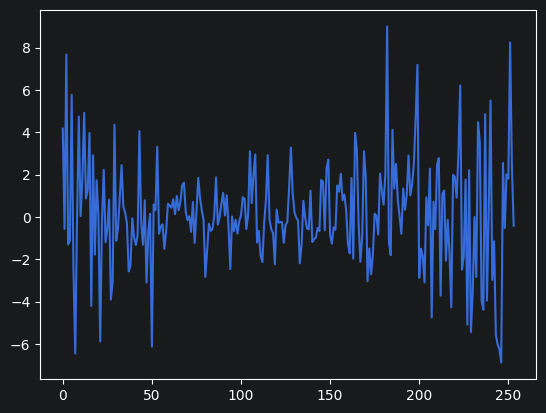

In [151]:
import matplotlib.pyplot as plt

plt.plot(df.trade_return_pct)

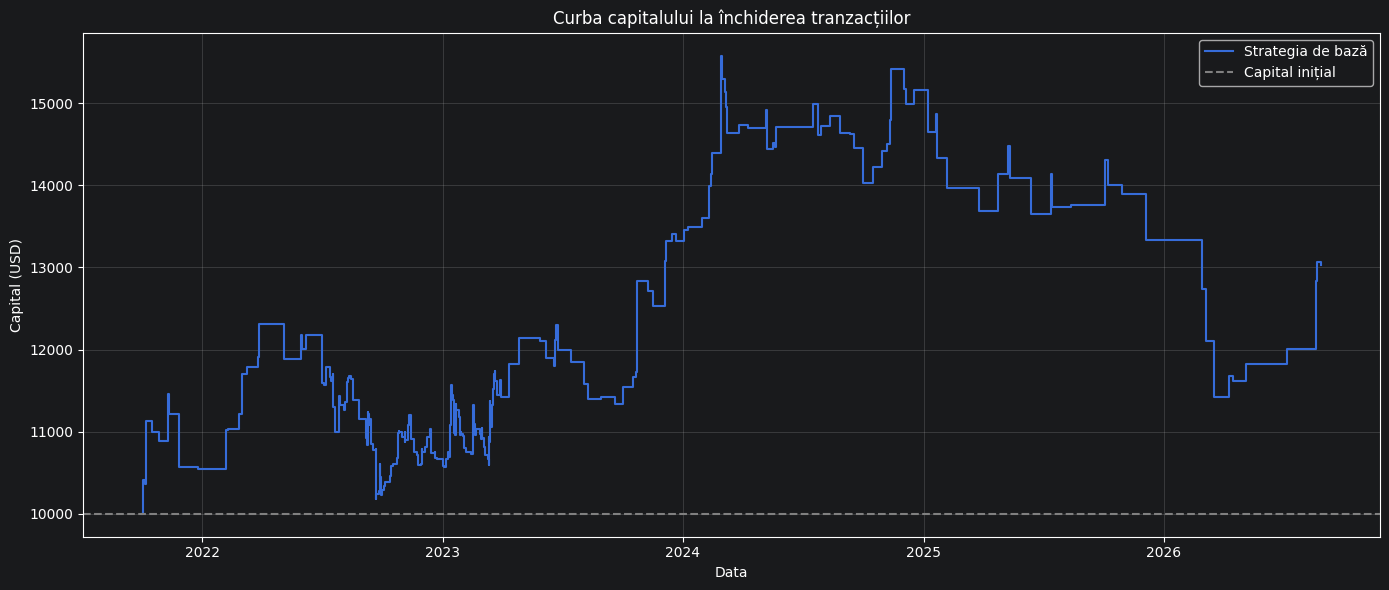

,Capital final (USD),PnL net (USD),Tranzacții,Semnale păstrate (%),Win rate net (%),Randament mediu net (%)
Variantă,,,,,,
Strategia de bază,13026.39765,3026.39765,254,100.0,50.393701,0.11915


In [152]:
import pandas as pd
import matplotlib.pyplot as plt


def plot_strategy_equity(
    trades,
    model=None,
    feature_cols=None,
    threshold=0.50,
    initial_capital=10_000,
    position_size=10_000,
):
    t = trades.loc[trades["trade_status"].eq("closed")].copy()

    if t.empty:
        raise ValueError("Nu există tranzacții închise.")

    t["entry_time"] = pd.to_datetime(t["entry_time"], utc=True)
    t["exit_time"] = pd.to_datetime(t["exit_time"], utc=True)
    t = t.sort_values("exit_time", kind="stable").reset_index(drop=True)

    net_return = t["trade_return"]  # Include deja costurile simulatorului.
    pnl = net_return * position_size
    dates = [t["entry_time"].min(), *t["exit_time"].tolist()]

    selections = {
        "Strategia de bază": pd.Series(True, index=t.index),
    }

    if model is not None:
        if feature_cols is None:
            feature_cols = list(model.feature_names_in_)

        positive_class = list(model.classes_).index(1)
        p_profit = model.predict_proba(t[list(feature_cols)])[:, positive_class]

        selections[f"Strategie + meta-model (prag {threshold:.0%})"] = (
            pd.Series(p_profit, index=t.index).ge(threshold)
        )

    fig, ax = plt.subplots(figsize=(14, 6))
    summary = []

    for name, accepted in selections.items():
        # Un semnal respins are PnL zero, pe aceeași axă de timp.
        selected_pnl = pnl.where(accepted, 0.0)
        equity = initial_capital + selected_pnl.cumsum()
        accepted_returns = net_return.loc[accepted]

        ax.step(
            dates,
            [initial_capital, *equity.tolist()],
            where="post",
            linewidth=1.5,
            label=name,
        )

        summary.append({
            "Variantă": name,
            "Capital final (USD)": equity.iloc[-1],
            "PnL net (USD)": selected_pnl.sum(),
            "Tranzacții": int(accepted.sum()),
            "Semnale păstrate (%)": 100 * accepted.mean(),
            "Win rate net (%)": 100 * accepted_returns.gt(0).mean(),
            "Randament mediu net (%)": 100 * accepted_returns.mean(),
        })

    ax.axhline(
        initial_capital, color="gray", linestyle="--", label="Capital inițial"
    )
    ax.set(title="Curba capitalului la închiderea tranzacțiilor",
           xlabel="Data", ylabel="Capital (USD)")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

    return pd.DataFrame(summary).set_index("Variantă")

plot_strategy_equity(df)

In [153]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

baseline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(penalty="l2", C=1.0, max_iter=1000),
)

from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

cat_model = CatBoostClassifier(
    iterations=150,
    depth=2,
    learning_rate=0.03,
    l2_leaf_reg=10,
    loss_function="Logloss",
    random_seed=42,
    verbose=False,
)

In [154]:
from sklearn.model_selection import train_test_split

trades = df.sort_values("signal_time").reset_index(drop=True).copy()

trades["di_diff"] = trades["plus_di"] - trades["minus_di"]
trades["atr_rel"] = trades["atr_value"] / trades["close"]
trades["ema_distance"] = trades["close"] / trades["ema200"] - 1

features = [
    "adx_value",
    "di_diff",
    "long_breakout_atr",
    "ema_distance",

     "aggr_imbalance_notional",
        "tick_imbalance_volume",
        "aggr_classified_frac_notional",
        "bar_duration_s",
        "trade_intensity_per_s",
        "avg_trade_size",

            "quote_spread_bps",
        "quote_twa_spread_bps",
        "depth_imbalance_10bps",
        "depth_imbalance_25bps",
        "cost_buy_10000USDT_bps",
        "book_valid_time_frac",
]

train_events, test_events = train_test_split(
    trades, test_size=0.30, shuffle=False
)

test_start = test_events["signal_time"].iloc[0]
train_events = train_events.loc[train_events["exit_time"] < test_start]

X_train = train_events[features]
y_train = train_events["trade_return"].gt(0).astype("int8")

X_test = test_events[features]
y_test = test_events["trade_return"].gt(0).astype("int8")

baseline.fit(X_train, y_train)
cat_model.fit(X_train, y_train)

/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['quote_spread_bps' 'quote_twa_spread_bps' 'depth_imbalance_10bps'
 'depth_imbalance_25bps' 'cost_buy_10000USDT_bps' 'book_valid_time_frac']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


CatBoostClassifier(depth=2, iterations=150, l2_leaf_reg=10, learning_rate=0.03, loss_function='Logloss', random_seed=42, verbose=False)

In [155]:
list(trades.columns)

['bar_id',
 'series_id',
 'bar_type',
 'bar_seq',
 'segment_id',
 'bar_start_us',
 'bar_end_us',
 'first_trade_ts_us',
 'last_trade_ts_us',
 'first_trade_id',
 'last_trade_id',
 'open',
 'high',
 'low',
 'close',
 'volume',
 'notional_usdt',
 'n_trades',
 'n_messages',
 'threshold_frozen',
 'complete',
 'bar_status',
 'bar_available_us',
 'decision_time_us',
 'bar_provenance',
 'bar_start',
 'bar_end',
 'bar_available',
 'decision_time',
 'ret_bars_1',
 'ret_bars_5',
 'ret_bars_20',
 'ret_5min',
 'ret_5min_ref_age_s',
 'ret_1h',
 'ret_1h_ref_age_s',
 'ret_4h',
 'ret_4h_ref_age_s',
 'ret_1d',
 'ret_1d_ref_age_s',
 'ret_7d',
 'ret_7d_ref_age_s',
 'ret_30d',
 'ret_30d_ref_age_s',
 'rv_1h',
 'rvol_1h',
 'rvol_ann_1h',
 'rv_1d',
 'rvol_1d',
 'rvol_ann_1d',
 'rv_7d',
 'rvol_7d',
 'rvol_ann_7d',
 'rv_30d',
 'rvol_30d',
 'rvol_ann_30d',
 'rv_bars_20',
 'rv_bars_100',
 'bar_duration_s',
 'trade_span_s',
 'avg_trade_size',
 'trade_intensity_per_s',
 'volume_per_s',
 'notional_per_s',
 'aggr_buy_

In [156]:
from sklearn.metrics import classification_report

y_pred_baseline = baseline.predict(X_test)
y_pred_cat_model = cat_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_baseline,
    labels=[0, 1],
    target_names=["Fără profit net", "Profit net pozitiv"],
    digits=3,
    zero_division=0,
))

print(classification_report(
    y_test,
    y_pred_cat_model,
    labels=[0, 1],
    target_names=["Fără profit net", "Profit net pozitiv"],
    digits=3,
    zero_division=0,
))

                    precision    recall  f1-score   support

   Fără profit net      0.466     0.794     0.587        34
Profit net pozitiv      0.632     0.279     0.387        43

          accuracy                          0.506        77
         macro avg      0.549     0.537     0.487        77
      weighted avg      0.558     0.506     0.475        77

                    precision    recall  f1-score   support

   Fără profit net      0.560     0.824     0.667        34
Profit net pozitiv      0.778     0.488     0.600        43

          accuracy                          0.636        77
         macro avg      0.669     0.656     0.633        77
      weighted avg      0.682     0.636     0.629        77



/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['quote_spread_bps' 'quote_twa_spread_bps' 'depth_imbalance_10bps'
 'depth_imbalance_25bps' 'cost_buy_10000USDT_bps' 'book_valid_time_frac']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [157]:
from sklearn.metrics import roc_auc_score

p_test_baseline = baseline.predict_proba(X_test)[:, 1]
print(f"ROC-AUC: {roc_auc_score(y_test, p_test_baseline):.4f}")

p_test_cat_model = cat_model.predict_proba(X_test)[:, 1]
print(f"ROC-AUC: {roc_auc_score(y_test, p_test_cat_model):.4f}")


ROC-AUC: 0.6170
ROC-AUC: 0.6477


/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['quote_spread_bps' 'quote_twa_spread_bps' 'depth_imbalance_10bps'
 'depth_imbalance_25bps' 'cost_buy_10000USDT_bps' 'book_valid_time_frac']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


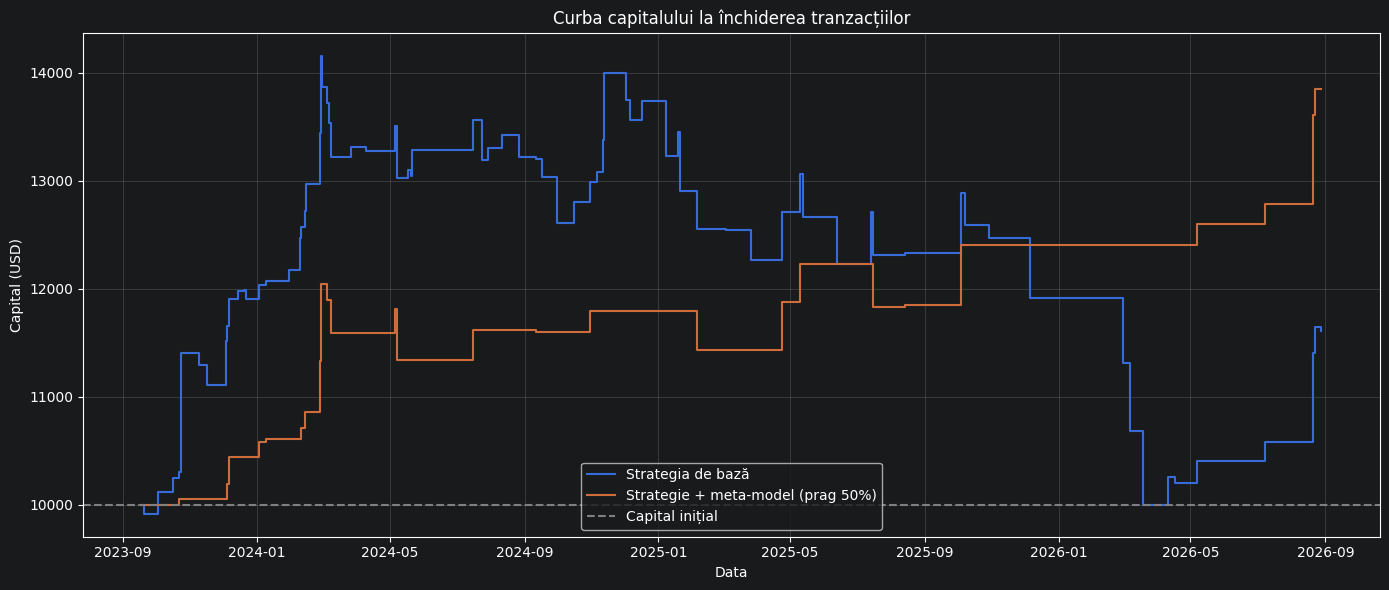

,Capital final (USD),PnL net (USD),Tranzacții,Semnale păstrate (%),Win rate net (%),Randament mediu net (%)
Variantă,,,,,,
Strategia de bază,11605.191596,1605.191596,77,100.000000,55.844156,0.208466
Strategie + meta-model (prag 50%),13846.864336,3846.864336,27,35.064935,77.777778,1.424765


In [165]:
plot_strategy_equity(test_events, cat_model, feature_cols=features, threshold=0.5)

In [159]:
from sklearn.metrics import log_loss, roc_auc_score

for name, p_test in [
    ("Baseline", p_test_baseline),
    ("CatBoost", p_test_cat_model),
]:
    auc = roc_auc_score(y_test, p_test)
    neg_loss = -log_loss(y_test, p_test, labels=[0, 1])

    print(f"{name:10s} | ROC-AUC: {auc:.4f} | Neg Log Loss: {neg_loss:.4f}")

Baseline   | ROC-AUC: 0.6170 | Neg Log Loss: -0.6967
CatBoost   | ROC-AUC: 0.6477 | Neg Log Loss: -0.6830
